# Semana 3 — Otimização de hiperparâmetros do SMA com Optuna

### Sintonia automatizada e análise de desempenho no Permutation Flow Shop

**Problema:** Permutation Flow Shop Scheduling (PFS) · **Objetivo:** minimizar o *Total Tardiness* · **Otimizador:** Optuna (TPE) · **Algoritmo:** Slime Mould Algorithm (SMA)

Neste experimento, investigamos como diferentes configurações do SMA influenciam a qualidade das soluções. O Optuna propõe combinações de hiperparâmetros, executa o algoritmo com as mesmas condições experimentais e seleciona a configuração que apresenta o menor atraso médio.

O notebook apresenta **o espaço de busca antes da sintonia**, exibe o progresso **trial por trial**, detalha os parâmetros selecionados e realiza uma avaliação final em instâncias reservadas, com tabelas e gráficos interpretativos.

**Referência:** Li, S. et al. (2020). *Slime mould algorithm: A new method for stochastic optimization*. *Future Generation Computer Systems*. https://doi.org/10.1016/j.future.2020.03.055

## 1. Organização do experimento

O Optuna não modifica as equações do SMA. Sua função é escolher **valores para os hiperparâmetros de execução** antes da busca, observando o desempenho de cada configuração nas instâncias de sintonia.

| Fase | O que acontece | Resultado esperado |
|---|---|---|
| 1. Preparação | Carregamento das instâncias, configuração do orçamento e das sementes | Ambiente reprodutível |
| 2. Espaço de busca | Definição dos valores admissíveis para `populacao` e `z` | Conjunto de configurações possíveis |
| 3. Sintonia | TPE propõe configurações; SMA é executado em múltiplas sementes | Score de cada trial |
| 4. Seleção | Configuração com menor Total Tardiness médio na sintonia | Parâmetros selecionados |
| 5. Avaliação | Comparação entre configuração fixa e configuração selecionada em instâncias reservadas | Qualidade, tempo e estabilidade |

**Controle experimental:** todas as execuções recebem o mesmo orçamento de avaliações exatas da função objetivo (CFO). As sementes de avaliação final são diferentes das sementes de sintonia. As instâncias de teste não são utilizadas na seleção dos hiperparâmetros.

## 2. Ambiente, dataset e configuração da execução

In [1]:
import sys, subprocess, importlib.util, time, json, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EXECUCAO_COMPLETA = True
SEMENTE_GLOBAL = 2026
np.random.seed(SEMENTE_GLOBAL)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.18})
POSSIVEIS_BASES = [Path('/kaggle/input/datasets/caiomoreiraban/dpfsp-dd/DPFSP_DD'),
                   Path('/kaggle/input/dpfsp-dd/DPFSP_DD'),
                   Path('/mnt/data/DPFSP_DD')]
DATASET_DIR = next((p for p in POSSIVEIS_BASES if (p/'Small').is_dir() and (p/'Large').is_dir()),None)
if DATASET_DIR is None and Path('/mnt/data/DPFSP_DD.zip').is_file():
    with zipfile.ZipFile('/mnt/data/DPFSP_DD.zip') as arquivo:
        arquivo.extractall('/mnt/data')
    DATASET_DIR = Path('/mnt/data/DPFSP_DD')
if DATASET_DIR is None and Path('/kaggle/input').exists():
    DATASET_DIR = next((p for p in Path('/kaggle/input').rglob('DPFSP_DD')
                        if (p/'Small').is_dir() and (p/'Large').is_dir()),None)
if DATASET_DIR is None:
    raise FileNotFoundError('Adicione DPFSP_DD aos dados de entrada do Kaggle.')
NOMES_INSTANCIAS = sorted(p.relative_to(DATASET_DIR).as_posix() for p in DATASET_DIR.rglob('*.txt'))
def listar_instancias(grupo=None):
    return [v for v in NOMES_INSTANCIAS if grupo is None or grupo in Path(v).parts]
def carregar_instancia(nome):
    return FlowShopEngine(*FlowShopEngine.carregar_instancia_txt(DATASET_DIR/nome))
print('Dataset:',DATASET_DIR,'| instâncias:',len(NOMES_INSTANCIAS))

if importlib.util.find_spec('optuna') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','optuna'])
import optuna
from optuna.importance import get_param_importances
optuna.logging.set_verbosity(optuna.logging.WARNING)
OUT=Path('/kaggle/working/semana3_optuna' if Path('/kaggle/working').exists() else '/mnt/data/semana3_optuna');OUT.mkdir(parents=True,exist_ok=True)
CONFIG={'trials':50 if EXECUCAO_COMPLETA else 3,
        'sementes_sintonia':[107,211,313] if EXECUCAO_COMPLETA else [107],
        'sementes_teste':[401,503,607,709,811] if EXECUCAO_COMPLETA else [401],
        'avaliacoes':3000 if EXECUCAO_COMPLETA else 300,
        'populacoes':[20,25,30,40,50,60], 'intervalo_z':[0.,.15],
        'mostrar_progresso_trials':True, 'log_cada':1}
print('='*76)
print('CONFIGURAÇÃO GERAL — SMA + OPTUNA')
print('='*76)
print(f'Modo de execução: {"COMPLETO" if EXECUCAO_COMPLETA else "VERIFICAÇÃO RÁPIDA"}')
print(f'Instâncias disponíveis: {len(NOMES_INSTANCIAS)} | Dataset: {DATASET_DIR}')
print(f'Número de trials: {CONFIG["trials"]}')
print(f'Orçamento por execução SMA: {CONFIG["avaliacoes"]:,} avaliações reais')
print(f'Sementes de sintonia: {CONFIG["sementes_sintonia"]}')
print(f'Sementes de teste: {CONFIG["sementes_teste"]}')
print(f'Parâmetros que serão ajustados: população e taxa de reinicialização z')
print(f'Arquivos de saída: {OUT}')
print('='*76)
display(pd.DataFrame([{'Configuração':k,'Valor':str(v)} for k,v in CONFIG.items()]))

Dataset: /kaggle/input/datasets/caiomoreiraban/dpfsp-dd/DPFSP_DD | instâncias: 1140
CONFIGURAÇÃO GERAL — SMA + OPTUNA
Modo de execução: COMPLETO
Instâncias disponíveis: 1140 | Dataset: /kaggle/input/datasets/caiomoreiraban/dpfsp-dd/DPFSP_DD
Número de trials: 50
Orçamento por execução SMA: 3,000 avaliações reais
Sementes de sintonia: [107, 211, 313]
Sementes de teste: [401, 503, 607, 709, 811]
Parâmetros que serão ajustados: população e taxa de reinicialização z
Arquivos de saída: /kaggle/working/semana3_optuna


,Configuração,Valor
0,trials,50
1,sementes_sintonia,"[107, 211, 313]"
2,sementes_teste,"[401, 503, 607, 709, 811]"
3,avaliacoes,3000
4,populacoes,"[20, 25, 30, 40, 50, 60]"
5,intervalo_z,"[0.0, 0.15]"
6,mostrar_progresso_trials,True
7,log_cada,1


## 3. FlowShopEngine e função objetivo

A `FlowShopEngine` lê os tempos de processamento e as datas de entrega, aplica uma permutação comum às máquinas e calcula o **Total Tardiness**. O SMA representa soluções por vetores de *Random Keys*, convertidos em sequências pela ordenação de suas componentes. O objetivo do Optuna será minimizar o fitness final médio retornado por esse avaliador.

In [2]:
import numpy as np
import os

class FlowShopEngine:   ### VERSÃO UNIFICADA TARDINESS + MAKESPAN
    def __init__(self, n_jobs, n_machines, proc_times, due_dates):
        """
        Engine unificada para problemas de Flow Shop.
        proc_times: Matriz (n_jobs, n_machines)
        due_dates: Vetor (n_jobs)
        """
        self.n_jobs = n_jobs
        self.n_machines = n_machines
        self.proc_times = proc_times
        self.due_dates = due_dates
        self.cfo_count = 0

    @staticmethod
    def carregar_instancia_txt(caminho_arquivo):
        """Lê N, M, tempos e datas de entrega, no formato TXT disponibilizado."""
        caminho_arquivo = Path(caminho_arquivo)
        if not caminho_arquivo.is_file():
            raise FileNotFoundError(f'Instância não encontrada: {caminho_arquivo}')
        with open(caminho_arquivo, 'r', encoding='utf-8') as f:
            linhas = [linha.strip() for linha in f if linha.strip()]
        num_jobs, num_machines = map(int, linhas[0].split())
        p_matrix = np.zeros((num_jobs, num_machines), dtype=int)
        idx_linha = 2  # A segunda linha indica fábricas; no modo PFS não é utilizada.
        for j in range(num_jobs):
            partes = linhas[idx_linha].split()
            if len(partes) != 2 * num_machines:
                raise ValueError(f'Tempos incompletos para o trabalho {j}')
            for i in range(0, len(partes), 2):
                maq, tempo = int(partes[i]), int(partes[i + 1])
                p_matrix[j, maq] = tempo
            idx_linha += 1
        while idx_linha < len(linhas) and linhas[idx_linha].lower() != 'duedate':
            idx_linha += 1
        if idx_linha >= len(linhas):
            raise ValueError(f'Seção Duedate ausente: {caminho_arquivo}')
        idx_linha += 1
        due_dates = np.array([int(linhas[idx_linha + j]) for j in range(num_jobs)], dtype=int)
        return num_jobs, num_machines, p_matrix, due_dates

    # =====================================================================
    # 2. CÁLCULO DO LOWER BOUND REAL (McMahon-Florian-Potts via EDD Preemptivo)
    # =====================================================================
    @staticmethod
    def calcular_lower_bound_potts(num_jobs, num_machines, p_matrix, due_dates):
        max_lateness_global = -float('inf')

        for m in range(num_machines):
            if m > 0:
                r_m = np.sum(p_matrix[:, :m], axis=1)
            else:
                r_m = np.zeros(num_jobs)

            if m < num_machines - 1:
                tempo_posterior = np.sum(p_matrix[:, m+1:], axis=1)
                d_m = due_dates - tempo_posterior
            else:
                d_m = due_dates.copy()

            p_m = p_matrix[:, m].astype(float)
            rem_p = p_m.copy()
            t = 0.0
            lateness_maquina = -float('inf')

            while np.sum(rem_p > 0) > 0:
                jobs_disponiveis = (r_m <= t) & (rem_p > 0)

                if not np.any(jobs_disponiveis):
                    proximas_liberacoes = r_m[(r_m > t) & (rem_p > 0)]
                    t = np.min(proximas_liberacoes)
                    continue

                indices_validos = np.where(jobs_disponiveis)[0]
                job_escolhido = indices_validos[np.argmin(d_m[indices_validos])]

                proximas_liberacoes = r_m[(r_m > t) & (rem_p > 0)]
                if len(proximas_liberacoes) > 0:
                    prox_release_evento = np.min(proximas_liberacoes)
                else:
                    prox_release_evento = float('inf')

                tempo_ate_terminar = rem_p[job_escolhido]
                tempo_ate_interrupcao = prox_release_evento - t
                delta_t = min(tempo_ate_terminar, tempo_ate_interrupcao)

                t += delta_t
                rem_p[job_escolhido] -= delta_t

                if rem_p[job_escolhido] <= 1e-7:
                    lateness_j = t - d_m[job_escolhido]
                    if lateness_j > lateness_maquina:
                        lateness_maquina = lateness_j

            if lateness_maquina > max_lateness_global:
                max_lateness_global = lateness_maquina

        return float(max_lateness_global)

    def bucket_sort_decode(self, keys):
        """Traduz chaves contínuas [0,1] em uma permutação de jobs."""
        return np.argsort(keys)

    def evaluate(self, keys, mode="PFS", objective="Tardiness"):
        self.cfo_count += 1
        n, m = self.n_jobs, self.n_machines

        # 1. Decodificação
        if mode == "PFS":
            seq = self.bucket_sort_decode(keys[:n])
            sequences = [seq] * m
        else:
            sequences = []
            for i in range(m):
                sequences.append(self.bucket_sort_decode(keys[i*n : (i+1)*n]))

        # 2. Cálculo das matrizes de tempo (Finish Times)
        # finish_times[i, j] é o tempo de término do job j na máquina i
        finish_times = np.zeros((m, n))

        # Primeira máquina (i=0)
        current_time = 0
        for job_idx in sequences[0]:
            current_time += self.proc_times[job_idx, 0]
            finish_times[0, job_idx] = current_time

        # Máquinas subsequentes (i=1 a m-1)
        for i in range(1, m):
            time_on_m = 0
            for job_idx in sequences[i]:
                # O job precisa terminar na máquina i-1 E a máquina i precisa estar livre
                start = max(time_on_m, finish_times[i-1, job_idx])
                finish_times[i, job_idx] = start + self.proc_times[job_idx, i]
                time_on_m = finish_times[i, job_idx]

        # 3. Retorno do Objetivo
        if objective == "Makespan":
            return np.max(finish_times[m-1, :])

        elif objective == "Tardiness":
            # Total Tardiness = soma de max(0, C_j - d_j)
            tardiness = np.maximum(0, finish_times[m-1, :] - self.due_dates)
            return np.sum(tardiness)

    def evaluate_with_permutation(self, permutation, objective="Tardiness"):
        self.cfo_count += 1
        n, m = self.n_jobs, self.n_machines

        # 1. A permutação já é fornecida, então é usada para todas as máquinas (PFS-like behavior)
        sequences = [permutation] * m

        # 2. Cálculo das matrizes de tempo (Finish Times)
        # finish_times[i, j] é o tempo de término do job j na máquina i
        finish_times = np.zeros((m, n))

        # Primeira máquina (i=0)
        current_time = 0
        for job_idx in sequences[0]:
            current_time += self.proc_times[job_idx, 0]
            finish_times[0, job_idx] = current_time

        # Máquinas subsequentes (i=1 a m-1)
        for i in range(1, m):
            time_on_m = 0
            for job_idx in sequences[i]:
                # O job precisa terminar na máquina i-1 E a máquina i precisa estar livre
                start = max(time_on_m, finish_times[i-1, job_idx])
                finish_times[i, job_idx] = start + self.proc_times[job_idx, i]
                time_on_m = finish_times[i, job_idx]

        # 3. Retorno do Objetivo
        if objective == "Makespan":
            return np.max(finish_times[m-1, :])

        elif objective == "Tardiness":
            # Total Tardiness = soma de max(0, C_j - d_j)
            tardiness = np.maximum(0, finish_times[m-1, :] - self.due_dates)
            return np.sum(tardiness)

## 4. Slime Mould Algorithm

O SMA procura sequências de trabalhos por meio de uma população de vetores contínuos. O melhor vetor encontrado é preservado, e os movimentos populacionais combinam pesos adaptativos, interações entre indivíduos e reinicialização aleatória.

Neste notebook, o Optuna ajusta **somente** o tamanho da população e o parâmetro `z`; os demais operadores do SMA permanecem inalterados. Assim, podemos investigar os efeitos dos hiperparâmetros mantendo a mesma função objetivo e o mesmo orçamento de avaliações.

In [3]:
# Núcleo de execução do Slime Mould Algorithm (SMA) para minimização.
# A representação de permutação é definida pela função de avaliação externa.
def sma_otimizar(fo, dimensao, populacao=30, avaliacoes=3000, seed=42,
                 z=0.03, controlador=None, janela_estagnacao=12,
                 observador=None, seletor=None):
    """Executa o SMA e retorna melhor fitness, posição, histórico e diagnósticos.

    `controlador(diversidade, estagnacao, z_base)` devolve z da geração.
    `observador(keys, fitness, geracao)` recebe apenas avaliações exatas.
    `seletor(X, restantes)` devolve (fitness_previsto, indices_para_avaliar).
    Sem `seletor`, todos os indivíduos da geração são avaliados pela função objetivo.
    """
    pop, dim = int(populacao), int(dimensao)
    if pop < 3 or dim < 1 or int(avaliacoes) < pop or not 0 <= z <= 1:
        raise ValueError('Dimensões, orçamento ou parâmetros inválidos')
    budget = int(avaliacoes)
    rng = np.random.default_rng(seed)
    X = rng.uniform(0.0, 1.0, (pop, dim))
    melhor_x = np.zeros(dim, dtype=float)
    melhor_y = float('inf')
    usadas = 0
    geracao = 0
    melhor_geracao = 0
    linhas = []
    empate_geracional = []
    reinicios = 0
    if seletor is None:
        total_geracoes = int(np.ceil(budget / pop))
    else:
        lote_estimado = max(1, int(np.ceil(pop * 0.4)))
        total_geracoes = 1 + int(np.ceil((budget-pop) / lote_estimado))

    while usadas < budget:
        geracao += 1
        # As posições são limitadas antes da avaliação dos candidatos.
        np.clip(X, 0.0, 1.0, out=X)
        empate_geracional.append(float(np.mean([dim-len(np.unique(v)) for v in X])))
        restantes = budget - usadas
        if seletor is None or geracao == 1:
            indices_exatos = np.arange(min(pop, restantes), dtype=int)
            fitness = np.full(pop, np.inf, dtype=float)
        else:
            previstos, indices_exatos = seletor(X, restantes)
            fitness = np.asarray(previstos, dtype=float).copy()
            indices_exatos = np.asarray(indices_exatos, dtype=int)
            if fitness.shape != (pop,) or not np.all(np.isfinite(fitness)):
                raise ValueError('Predições de fitness inválidas')
            if len(indices_exatos) < 1 or len(indices_exatos) > restantes:
                raise ValueError('Quantidade inválida de avaliações exatas')

        for i in indices_exatos:
            fitness[i] = float(fo(X[i]))
            usadas += 1
            if not np.isfinite(fitness[i]):
                raise ValueError('Fitness não finito')
            if observador is not None:
                observador(X[i].copy(), float(fitness[i]), geracao-1)
            if float(fitness[i]) < melhor_y:
                melhor_y = float(fitness[i])
                melhor_x = X[i].copy()
                melhor_geracao = geracao
        if not np.isfinite(melhor_y):
            raise RuntimeError('Melhor fitness não identificado')

        # Entrada da política de controle: diferença média de posições nas permutações.
        diversidade = float(np.mean(np.argsort(X, axis=1, kind='stable') !=
                                   np.argsort(melhor_x, kind='stable')))
        estagnacao = float(min(1.0, max(0, geracao-melhor_geracao) /
                               max(1, int(janela_estagnacao))))
        z_atual = float(np.clip(controlador(diversidade, estagnacao, float(z))
                                 if controlador is not None else z, 0, 1))
        linhas.append(dict(geracao=geracao-1, avaliacoes=usadas,
                           melhor=melhor_y, diversidade=diversidade,
                           estagnacao=estagnacao, z=z_atual,
                           empates_medio=empate_geracional[-1]))
        if usadas >= budget:
            break

        # Cálculo da matriz de pesos a partir do ranking.
        ordem = np.argsort(fitness, kind='stable')
        melhor_atual = float(fitness[ordem[0]])
        pior_atual = float(fitness[ordem[-1]])
        denominador = melhor_atual - pior_atual + np.finfo(float).eps
        W = np.ones_like(X)
        for pos, idx in enumerate(ordem):
            razao = (melhor_atual - float(fitness[idx])) / denominador if melhor_atual != pior_atual else 0.0
            termo = float(np.log10(razao + 1.0))
            sinal = 1.0 if pos + 1 <= pop/2 else -1.0
            for j in range(dim):
                W[idx, j] = 1.0 + sinal * rng.random() * termo

        a = float(np.arctanh(1.0 - geracao / total_geracoes))
        b = float(1.0 - geracao / total_geracoes)
        # Atualização sequencial, usando a mesma matriz de posições.
        for i in range(pop):
            if rng.random() < z_atual:
                X[i, :] = rng.random()  # reinicialização por escalar
                reinicios += 1
            else:
                p = float(np.tanh(abs(float(fitness[i]) - melhor_y)))
                vb = rng.uniform(-a, a, size=dim)
                vc = rng.uniform(-b, b, size=dim)
                for j in range(dim):
                    r = rng.random()
                    A = int(rng.integers(0, pop))
                    B = int(rng.integers(0, pop))
                    if r < p:
                        X[i, j] = melhor_x[j] + vb[j] * (W[i, j] * X[A, j] - X[B, j])
                    else:
                        X[i, j] = vc[j] * X[i, j]
    historico_df = pd.DataFrame(linhas)
    historico = historico_df[['avaliacoes', 'melhor']].to_numpy(dtype=float)
    return dict(fitness=melhor_y, melhor_posicao=melhor_x,
                historico=historico, historico_completo=historico_df,
                cfo=usadas, empates_medio=float(np.mean(empate_geracional)),
                reinicios=reinicios)

### 4.1. Testes básicos de integridade

Antes da sintonia, verificamos o número de avaliações, a manutenção do melhor fitness histórico, os limites das soluções e a equivalência entre avaliar as chaves e avaliar sua permutação decodificada.

In [4]:
def testar_sma():
    contagem=[0]
    def sphere(x):
        contagem[0]+=1
        return float(np.sum((x-0.25)**2))
    r=sma_otimizar(sphere,dimensao=6,populacao=10,avaliacoes=100,seed=17,z=.03)
    assert contagem[0]==r['cfo']==100
    assert np.all(np.diff(r['historico'][:,1])<=1e-12)
    assert np.isfinite(r['fitness'])
    assert np.all((r['melhor_posicao']>=0)&(r['melhor_posicao']<=1))
    eng=carregar_instancia(listar_instancias('Small')[0])
    keys=np.random.default_rng(34).random(eng.n_jobs)
    a=eng.evaluate(keys,mode='PFS',objective='Tardiness')
    b=eng.evaluate_with_permutation(eng.bucket_sort_decode(keys))
    assert a==b
    return r,eng
r_teste,engine_teste=testar_sma()
print('Testes de integridade: OK | 100 avaliações | Sphere:',round(r_teste['fitness'],6))
print('Exemplo:',engine_teste.n_jobs,'trabalhos,',engine_teste.n_machines,'máquinas')

Testes de integridade: OK | 100 avaliações | Sphere: 0.041356
Exemplo: 10 trabalhos, 2 máquinas


## 5. Instâncias e separação entre sintonia e teste

As instâncias **Small** selecionadas participam da escolha dos hiperparâmetros. As instâncias **Large** são reservadas para avaliar se a configuração escolhida mantém bom desempenho em problemas maiores. Esse desenho testa transferência entre tamanhos de problema; a diferença de escala deve ser considerada ao interpretar os resultados.

In [5]:
SMALL=listar_instancias('Small')
INSTANCIAS_SINTONIA=SMALL[:3] if EXECUCAO_COMPLETA else SMALL[:1]
INSTANCIAS_TESTE=[nome for nome in ['Large/Ta001_2.txt','Large/Ta011_2.txt','Large/Ta031_2.txt','Large/Ta041_2.txt'] if nome in NOMES_INSTANCIAS]
INSTANCIAS_TESTE=INSTANCIAS_TESTE if EXECUCAO_COMPLETA else INSTANCIAS_TESTE[:1]
print('Sintonia:',INSTANCIAS_SINTONIA)
print('Teste reservado:',INSTANCIAS_TESTE)
assert set(INSTANCIAS_SINTONIA).isdisjoint(INSTANCIAS_TESTE)
print('\nINSTÂNCIAS UTILIZADAS')
for grupo,nomes in [('SINTONIA',INSTANCIAS_SINTONIA),('TESTE RESERVADO',INSTANCIAS_TESTE)]:
    print(f'\n{grupo} ({len(nomes)} instâncias)')
    for nome in nomes:
        eng=carregar_instancia(nome)
        print(f'  • {nome}: {eng.n_jobs} trabalhos × {eng.n_machines} máquinas')
N_EXEC_SINTONIA = len(INSTANCIAS_SINTONIA) * len(CONFIG['sementes_sintonia'])
N_AVALIACOES_TOTAIS = CONFIG['trials'] * N_EXEC_SINTONIA * CONFIG['avaliacoes']
print('\nCUSTO PROGRAMADO DA SINTONIA')
print(f'  Execuções de SMA por trial: {N_EXEC_SINTONIA}')
print(f'  Total de execuções de SMA: {CONFIG["trials"] * N_EXEC_SINTONIA}')
print(f'  Avaliações reais estimadas: {N_AVALIACOES_TOTAIS:,}'.replace(',', '.'))
print(f'  Execuções da comparação final: {2 * len(INSTANCIAS_TESTE) * len(CONFIG["sementes_teste"])}')

Sintonia: ['Small/I_2_10_2_1.txt', 'Small/I_2_10_2_2.txt', 'Small/I_2_10_2_3.txt']
Teste reservado: ['Large/Ta001_2.txt', 'Large/Ta011_2.txt', 'Large/Ta031_2.txt', 'Large/Ta041_2.txt']

INSTÂNCIAS UTILIZADAS

SINTONIA (3 instâncias)
  • Small/I_2_10_2_1.txt: 10 trabalhos × 2 máquinas
  • Small/I_2_10_2_2.txt: 10 trabalhos × 2 máquinas
  • Small/I_2_10_2_3.txt: 10 trabalhos × 2 máquinas

TESTE RESERVADO (4 instâncias)
  • Large/Ta001_2.txt: 20 trabalhos × 5 máquinas
  • Large/Ta011_2.txt: 20 trabalhos × 10 máquinas
  • Large/Ta031_2.txt: 50 trabalhos × 5 máquinas
  • Large/Ta041_2.txt: 50 trabalhos × 10 máquinas

CUSTO PROGRAMADO DA SINTONIA
  Execuções de SMA por trial: 9
  Total de execuções de SMA: 450
  Avaliações reais estimadas: 1.350.000
  Execuções da comparação final: 40


## 6. Hiperparâmetros que serão otimizados

O espaço de busca contempla duas variáveis com papéis distintos:

| Hiperparâmetro | Valores considerados | Efeito no SMA | Interpretação prática |
|---|---|---|---|
| `populacao` | **20, 25, 30, 40, 50 ou 60** indivíduos | Quantidade de soluções mantidas em cada geração | Populações maiores exploram mais indivíduos por geração, porém realizam menos gerações no mesmo orçamento |
| `z` | **Qualquer valor entre 0,00 e 0,15** | Probabilidade de reinicializar um indivíduo | `z = 0,03` representa 3% de chance de reinicialização por indivíduo em cada geração |

A população é amostrada como **variável categórica**, enquanto `z` é uma **variável contínua**. Isso significa que o Optuna pode propor números como `z = 0,0471`, não apenas os exemplos da tabela seguinte.

### 6.1. Exemplos de configurações possíveis

Os exemplos a seguir são **ilustrativos**: não são os resultados das trials, nem uma lista fechada de combinações. Servem para antecipar como os hiperparâmetros afetam o número de gerações e a reinicialização esperada.

In [6]:
# Apresentação do espaço de busca e dos efeitos esperados dos parâmetros.
TABELA_PARAMETROS = pd.DataFrame([
    {'Hiperparâmetro': 'populacao', 'Tipo': 'Categórico',
     'Domínio de busca': ', '.join(map(str, CONFIG['populacoes'])),
     'Valor baseline': 30, 'Interpretação': 'Indivíduos por geração'},
    {'Hiperparâmetro': 'z', 'Tipo': 'Contínuo',
     'Domínio de busca': f'{CONFIG["intervalo_z"][0]:.2f} até {CONFIG["intervalo_z"][1]:.2f}',
     'Valor baseline': 0.03, 'Interpretação': 'Probabilidade de reinicialização'}
])
display(TABELA_PARAMETROS)

EXEMPLOS_CONFIGURACAO = [
    (20, 0.00, 'Sem reinicialização aleatória'),
    (25, 0.01, 'Reinicialização pouco frequente'),
    (30, 0.03, 'Configuração de referência'),
    (40, 0.05, 'Reinicialização moderada'),
    (50, 0.10, 'Reinicialização elevada'),
    (60, 0.15, 'Limite superior do espaço de busca')
]
EXEMPLOS = pd.DataFrame([
    {'População': pop,
     'z': z,
     'z (%)': 100*z,
     'Gerações aproximadas': int(np.ceil(CONFIG['avaliacoes']/pop)),
     'Reinicializações esperadas por geração': pop*z,
     'Leitura': descricao}
    for pop,z,descricao in EXEMPLOS_CONFIGURACAO
])
print('EXEMPLOS DE CONFIGURAÇÕES QUE O OPTUNA PODE EXPLORAR')
display(EXEMPLOS.style.format({'z':'{:.3f}', 'z (%)':'{:.1f}%',
                               'Reinicializações esperadas por geração':'{:.2f}'}))
print('Observação: o orçamento de avaliações permanece fixo em', CONFIG['avaliacoes'],
      'para qualquer tamanho de população.')
print('O número de reinicializações apresentado é um valor esperado, não uma contagem garantida.')

,Hiperparâmetro,Tipo,Domínio de busca,Valor baseline,Interpretação
0,populacao,Categórico,"20, 25, 30, 40, 50, 60",30.00,Indivíduos por geração
1,z,Contínuo,0.00 até 0.15,0.03,Probabilidade de reinicialização


EXEMPLOS DE CONFIGURAÇÕES QUE O OPTUNA PODE EXPLORAR


,População,z,z (%),Gerações aproximadas,Reinicializações esperadas por geração,Leitura
0,20,0.000,0.0%,150,0.00,Sem reinicialização aleatória
1,25,0.010,1.0%,120,0.25,Reinicialização pouco frequente
2,30,0.030,3.0%,100,0.90,Configuração de referência
3,40,0.050,5.0%,75,2.00,Reinicialização moderada
4,50,0.100,10.0%,60,5.00,Reinicialização elevada
5,60,0.150,15.0%,50,9.00,Limite superior do espaço de busca


Observação: o orçamento de avaliações permanece fixo em 3000 para qualquer tamanho de população.
O número de reinicializações apresentado é um valor esperado, não uma contagem garantida.


### 6.2. Como uma trial é pontuada?

Em cada trial, o TPE propõe um par (`populacao`, `z`). O SMA é executado em **todas as instâncias de sintonia** e em **todas as sementes de sintonia**. O resultado da trial é a média aritmética dos melhores fitness finais:

\[
\operatorname{score}(\theta)=\frac{1}{|I|\,|S|}
\sum_{i\in I}\sum_{s\in S} \operatorname{TT}_{i,s}(\theta),
\qquad \theta=(\operatorname{populacao},z).
\]

**Quanto menor o score, melhor a configuração.** Utilizar as mesmas sementes em todas as trials reduz a variabilidade da comparação. Como os valores de fitness diferem entre instâncias, essa média reflete também a escala de cada uma delas.

Durante a sintonia, o notebook exibirá **número da trial, população, `z`, score, dispersão das execuções, tempo e melhor score até o momento**. Ao final, apresenta a classificação das melhores configurações.

In [7]:
def pontuar_configuracao(parametros, instancias, sementes):
    notas=[]
    for nome in instancias:
        eg=carregar_instancia(nome)
        for seed in sementes:
            resultado=sma_otimizar(lambda x:eg.evaluate(x),eg.n_jobs,**parametros,
                                   seed=seed,avaliacoes=CONFIG['avaliacoes'])
            assert resultado['cfo']==CONFIG['avaliacoes']
            notas.append({'instancia':nome,'semente':seed,'fitness':resultado['fitness']})
    return float(np.mean([v['fitness'] for v in notas])),pd.DataFrame(notas)

def objetivo_optuna(trial):
    inicio_trial=time.perf_counter()
    parametros={
        'populacao':trial.suggest_categorical('populacao',CONFIG['populacoes']),
        'z':trial.suggest_float('z',*CONFIG['intervalo_z'])
    }
    score,detalhes=pontuar_configuracao(parametros,INSTANCIAS_SINTONIA,CONFIG['sementes_sintonia'])
    trial.set_user_attr('desvio_fitness',float(detalhes.fitness.std(ddof=0)))
    trial.set_user_attr('n_execucoes',len(detalhes))
    trial.set_user_attr('tempo_trial_s',time.perf_counter()-inicio_trial)
    trial.set_user_attr('avaliacoes_por_execucao',CONFIG['avaliacoes'])
    return score

def registrar_trial(estudo,trial):
    if not CONFIG['mostrar_progresso_trials'] or (trial.number+1)%CONFIG['log_cada']!=0:
        return
    melhor=estudo.best_trial
    atual=trial.number==melhor.number
    marca='  <-- NOVO MELHOR' if atual else ''
    print(f'[Trial {trial.number+1:02d}/{CONFIG["trials"]:02d}] '
          f'pop={trial.params["populacao"]:>2d} | '
          f'z={trial.params["z"]:.5f} ({trial.params["z"]*100:.2f}%) | '
          f'TT médio={trial.value:,.2f} | '
          f'dp={trial.user_attrs["desvio_fitness"]:,.2f} | '
          f'tempo={trial.user_attrs["tempo_trial_s"]:.2f}s | '
          f'melhor até agora={melhor.value:,.2f}{marca}')

print('\n'+'='*85)
print('INICIANDO A SINTONIA AUTOMÁTICA COM OPTUNA')
print('='*85)
print(f'Método de amostragem: TPE | Direção: minimizar o Total Tardiness médio')
print(f'Trials previstas: {CONFIG["trials"]} | Execuções por trial: {N_EXEC_SINTONIA}')
print(f'Espaço de busca: população ∈ {CONFIG["populacoes"]} | z ∈ {CONFIG["intervalo_z"]}')
print('Todas as trials utilizam as mesmas instâncias, sementes e orçamento de avaliações.')
print('-'*85)
estudo=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(seed=2026))
inicio=time.perf_counter()
estudo.optimize(objetivo_optuna,n_trials=CONFIG['trials'],
               callbacks=[registrar_trial],show_progress_bar=False)
TEMPO_SINTONIA=time.perf_counter()-inicio
PARAMETROS_OTIMOS=dict(estudo.best_params)
TRIALS=estudo.trials_dataframe(attrs=('number','value','params','state','user_attrs'))
TRIALS.to_csv(OUT/'trials_optuna.csv',index=False)
print('\n'+'='*85)
print('SINTONIA CONCLUÍDA — CONFIGURAÇÃO SELECIONADA')
print('='*85)
print(f'Trials concluídas: {len(estudo.trials)}')
print(f'Melhor trial: {estudo.best_trial.number+1} de {CONFIG["trials"]}')
print(f'Menor Total Tardiness médio: {estudo.best_value:,.3f}')
print(f'População: {PARAMETROS_OTIMOS["populacao"]} indivíduos')
print(f'z: {PARAMETROS_OTIMOS["z"]:.6f} ({PARAMETROS_OTIMOS["z"]*100:.3f}% de reinicialização)')
print(f'Gerações aproximadas com o orçamento adotado: '
      f'{int(np.ceil(CONFIG["avaliacoes"]/PARAMETROS_OTIMOS["populacao"]))}')
print(f'Tempo total de sintonia: {TEMPO_SINTONIA:.2f} segundos')
print(f'Histórico completo salvo em: {OUT/"trials_optuna.csv"}')


INICIANDO A SINTONIA AUTOMÁTICA COM OPTUNA
Método de amostragem: TPE | Direção: minimizar o Total Tardiness médio
Trials previstas: 50 | Execuções por trial: 9
Espaço de busca: população ∈ [20, 25, 30, 40, 50, 60] | z ∈ [0.0, 0.15]
Todas as trials utilizam as mesmas instâncias, sementes e orçamento de avaliações.
-------------------------------------------------------------------------------------
[Trial 01/50] pop=60 | z=0.02972 (2.97%) | TT médio=2,211.22 | dp=268.56 | tempo=3.39s | melhor até agora=2,211.22  <-- NOVO MELHOR
[Trial 02/50] pop=20 | z=0.13411 (13.41%) | TT médio=2,208.67 | dp=268.44 | tempo=3.45s | melhor até agora=2,208.67  <-- NOVO MELHOR
[Trial 03/50] pop=60 | z=0.00459 (0.46%) | TT médio=2,209.44 | dp=268.87 | tempo=3.45s | melhor até agora=2,208.67
[Trial 04/50] pop=50 | z=0.00703 (0.70%) | TT médio=2,213.00 | dp=269.60 | tempo=3.41s | melhor até agora=2,208.67
[Trial 05/50] pop=30 | z=0.03861 (3.86%) | TT médio=2,209.11 | dp=268.03 | tempo=3.46s | melhor até ago

### 6.3. Classificação e distribuição das trials

A tabela a seguir ordena as configurações pelo score obtido. Além dos parâmetros, apresenta o desvio-padrão entre as execuções e o tempo de cada trial. A comparação com a mediana de todas as trials ajuda a identificar se a melhor configuração se destaca do conjunto explorado.

In [8]:
CLASSIFICACAO=TRIALS.copy().sort_values('value').reset_index(drop=True)
COLUNAS_RESULTADOS=['number','params_populacao','params_z','value',
                     'user_attrs_desvio_fitness','user_attrs_tempo_trial_s']
CLASSIFICACAO=CLASSIFICACAO[COLUNAS_RESULTADOS].rename(columns={
    'number':'Trial (base 0)','params_populacao':'População',
    'params_z':'z','value':'Total Tardiness médio',
    'user_attrs_desvio_fitness':'Desvio-padrão',
    'user_attrs_tempo_trial_s':'Tempo da trial (s)'})
CLASSIFICACAO['Trial']=CLASSIFICACAO['Trial (base 0)']+1
CLASSIFICACAO=CLASSIFICACAO[['Trial','População','z','Total Tardiness médio',
                            'Desvio-padrão','Tempo da trial (s)']]
print('TOP 10 CONFIGURAÇÕES DO OPTUNA')
display(CLASSIFICACAO.head(10).style.format({
    'z':'{:.5f}','Total Tardiness médio':'{:,.2f}',
    'Desvio-padrão':'{:,.2f}','Tempo da trial (s)':'{:.2f}'}))

scores=TRIALS['value'].to_numpy(dtype=float)
print('\nRESUMO DAS TRIALS')
print(f'Melhor score: {np.min(scores):,.2f}')
print(f'Score mediano: {np.median(scores):,.2f}')
print(f'Pior score: {np.max(scores):,.2f}')
print(f'Desvio-padrão entre trials: {np.std(scores):,.2f}')
print(f'Trials dentro de 1% do melhor score: '
      f'{np.sum(scores <= np.min(scores)*1.01)} de {len(scores)}')
print('Frequência de tamanhos de população testados:')
display(TRIALS['params_populacao'].value_counts().sort_index().rename_axis('População').to_frame('Trials'))
CLASSIFICACAO.to_csv(OUT/'classificacao_trials.csv',index=False)

TOP 10 CONFIGURAÇÕES DO OPTUNA


,Trial,População,z,Total Tardiness médio,Desvio-padrão,Tempo da trial (s)
0,2,20,0.13411,"2,208.67",268.44,3.45
1,39,20,0.13495,"2,208.67",268.44,3.25
2,37,20,0.13519,"2,208.67",268.44,3.25
3,13,20,0.02934,"2,208.78",268.50,3.57
4,43,20,0.13755,"2,208.89",268.56,3.26
5,40,20,0.13866,"2,208.89",268.56,3.23
6,16,50,0.10013,"2,209.00",268.62,3.29
7,24,40,0.11591,"2,209.00",267.97,3.25
8,7,60,0.12818,"2,209.11",268.03,3.22
9,5,30,0.03861,"2,209.11",268.03,3.46



RESUMO DAS TRIALS
Melhor score: 2,208.67
Score mediano: 2,210.89
Pior score: 2,248.67
Desvio-padrão entre trials: 5.76
Trials dentro de 1% do melhor score: 49 de 50
Frequência de tamanhos de população testados:


,Trials
População,
20,19
25,5
30,4
40,7
50,8
60,7


## 7. Histórico da otimização

O gráfico mostra o score de cada trial e o **melhor score acumulado**. Pontos mais baixos indicam configurações melhores. A curva acumulada só diminui quando o Optuna encontra uma nova combinação que supera as anteriores.

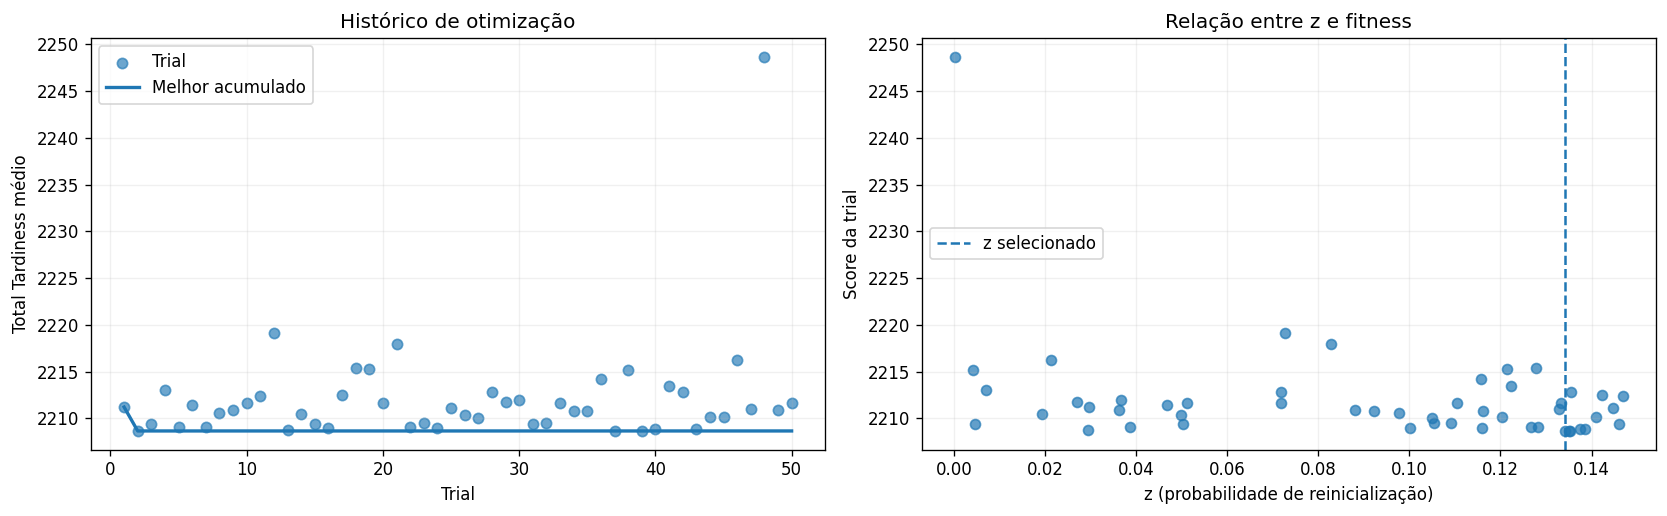

In [9]:
df=TRIALS.sort_values('number').copy()
df['melhor_acumulado']=df['value'].cummin()
fig,axs=plt.subplots(1,2,figsize=(14,4.4))
axs[0].scatter(df['number']+1,df['value'],alpha=.65,s=38,label='Trial')
axs[0].plot(df['number']+1,df['melhor_acumulado'],lw=2,label='Melhor acumulado')
axs[0].set(xlabel='Trial',ylabel='Total Tardiness médio',title='Histórico de otimização');axs[0].legend()
axs[1].scatter(df['params_z'],df['value'],alpha=.7)
axs[1].axvline(PARAMETROS_OTIMOS['z'],linestyle='--',label='z selecionado')
axs[1].set(xlabel='z (probabilidade de reinicialização)',ylabel='Score da trial',title='Relação entre z e fitness');axs[1].legend()
plt.tight_layout();plt.show()

### 7.1. Importância estimada dos hiperparâmetros

O gráfico compara a importância estatística estimada de `populacao` e `z` na variação dos scores. Essa importância depende das trials realizadas e **não deve ser interpretada como prova causal**. O segundo gráfico permite examinar o desempenho observado por tamanho da população.

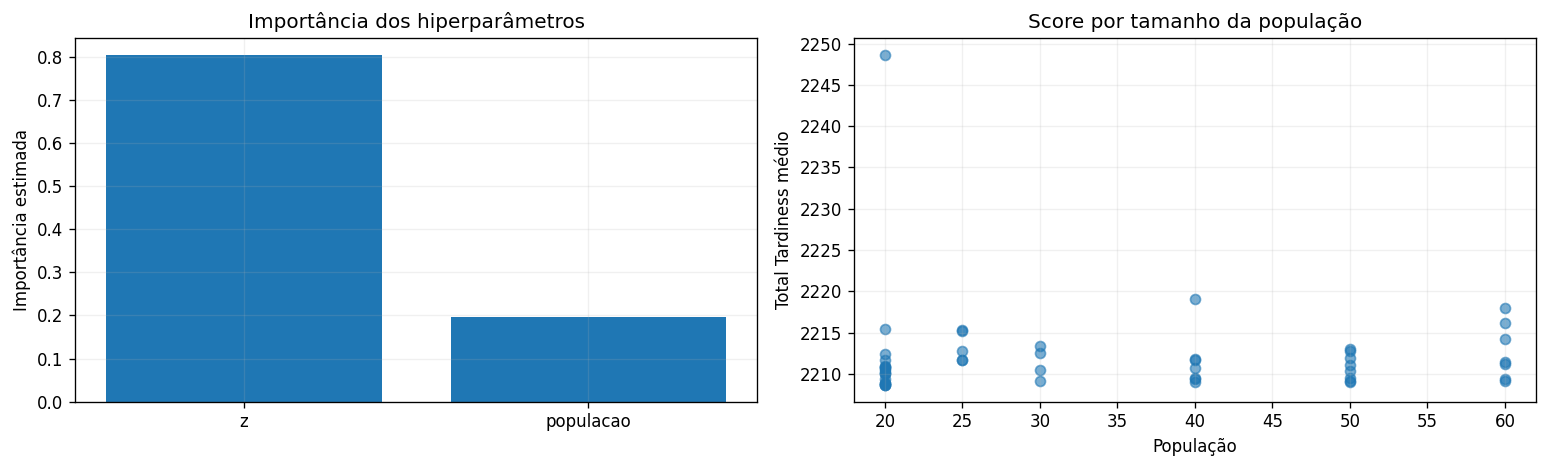

Importâncias: {'z': 0.8029175565648334, 'populacao': 0.1970824434351666}


In [10]:
try:
    importancias=get_param_importances(estudo)
except Exception:
    importancias={k:np.nan for k in PARAMETROS_OTIMOS}
fig,axs=plt.subplots(1,2,figsize=(13,4))
axs[0].bar(list(importancias),list(importancias.values()))
axs[0].set(ylabel='Importância estimada',title='Importância dos hiperparâmetros')
axs[1].scatter(df['params_populacao'].astype(float),df['value'],alpha=.6)
axs[1].set(xlabel='População',ylabel='Total Tardiness médio',title='Score por tamanho da população')
plt.tight_layout();plt.show()
print('Importâncias:',importancias)

### 7.2. Mapa das regiões exploradas pelo Optuna

O painel a seguir agrupa as trials por tamanho de população e por faixas de `z`. Cada célula mostra o melhor score observado entre as configurações que caíram naquela região. Células sem ensaio permanecem em branco.

O mapa ajuda a identificar regiões promissoras, mas **não substitui** a avaliação final em instâncias reservadas.

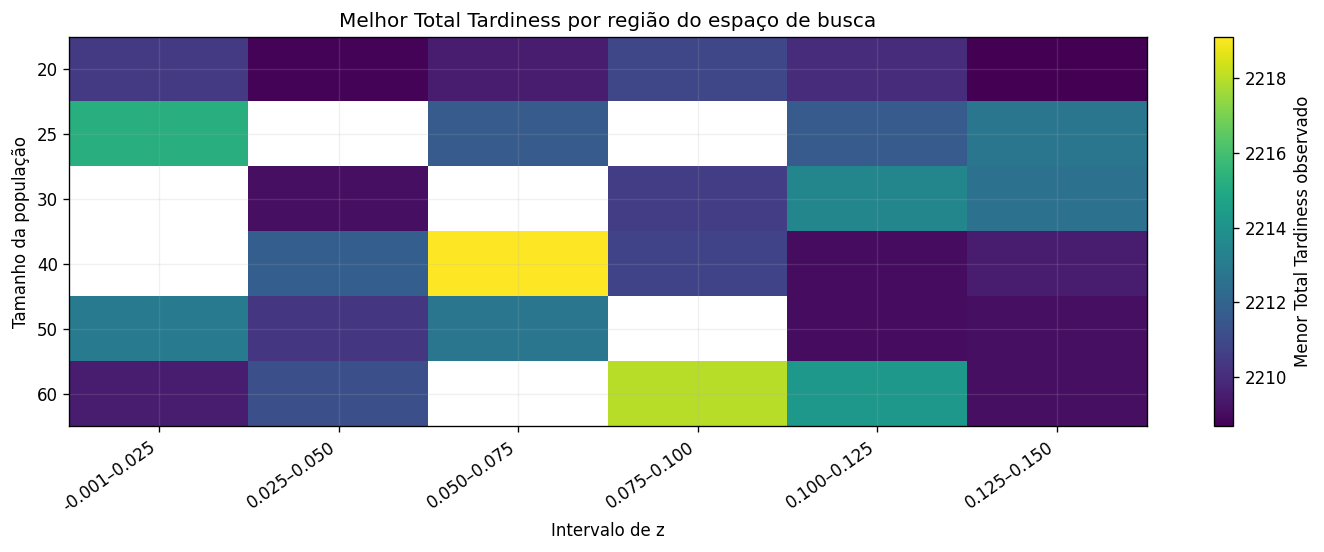

In [11]:
DF_MAPA=TRIALS[['params_populacao','params_z','value']].copy()
BORDAS=np.linspace(CONFIG['intervalo_z'][0],CONFIG['intervalo_z'][1],7)
DF_MAPA['faixa_z']=pd.cut(DF_MAPA['params_z'],bins=BORDAS,include_lowest=True)
MAPA=DF_MAPA.pivot_table(index='params_populacao',columns='faixa_z',values='value',
                          aggfunc='min',observed=False)
MAPA=MAPA.reindex(CONFIG['populacoes'])
fig,ax=plt.subplots(figsize=(12,4.7))
mat=np.ma.masked_invalid(MAPA.to_numpy(dtype=float))
im=ax.imshow(mat,aspect='auto',interpolation='nearest')
ax.set_yticks(np.arange(len(MAPA.index)))
ax.set_yticklabels([str(v) for v in MAPA.index])
ax.set_xticks(np.arange(len(MAPA.columns)))
ax.set_xticklabels([f'{iv.left:.3f}–{iv.right:.3f}' for iv in MAPA.columns],rotation=35,ha='right')
ax.set(xlabel='Intervalo de z',ylabel='Tamanho da população',
       title='Melhor Total Tardiness por região do espaço de busca')
fig.colorbar(im,ax=ax,label='Menor Total Tardiness observado')
plt.tight_layout();plt.show()

## 8. Avaliação final: configuração fixa × parâmetros selecionados

A configuração escolhida pelo Optuna é comparada com um SMA de referência (`populacao = 30` e `z = 0,03`), mantendo as mesmas instâncias, sementes e orçamento. As instâncias **Large** foram reservadas para este momento e não participaram da sintonia.

A avaliação registra **Total Tardiness, tempo de execução e número médio de chaves empatadas**. As duas configurações são executadas nas mesmas sementes para facilitar a interpretação das diferenças.

In [12]:
BASELINE={'populacao':30,'z':.03}
print('\n'+'='*80)
print('AVALIAÇÃO FINAL EM INSTÂNCIAS RESERVADAS')
print('='*80)
print('Configuração fixa:', BASELINE)
print('Configuração Optuna:', PARAMETROS_OTIMOS)
print('Sementes de avaliação:', CONFIG['sementes_teste'])
print('Cada execução utiliza', CONFIG['avaliacoes'], 'avaliações da função objetivo.')
print('-'*80)
registros=[];CURVAS={}
for nome in INSTANCIAS_TESTE:
    for seed in CONFIG['sementes_teste']:
        for metodo,parametros in [('SMA baseline',BASELINE),('SMA + Optuna',PARAMETROS_OTIMOS)]:
            eng=carregar_instancia(nome);ini=time.perf_counter()
            r=sma_otimizar(lambda x:eng.evaluate(x),eng.n_jobs,avaliacoes=CONFIG['avaliacoes'],
                           seed=seed,**parametros)
            assert eng.cfo_count==r['cfo']==CONFIG['avaliacoes']
            registros.append({'instancia':nome,'semente':seed,'metodo':metodo,
                              'fitness':r['fitness'],'tempo_s':time.perf_counter()-ini,
                              'empates_medio':r['empates_medio']})
            CURVAS[(nome,seed,metodo)]=r['historico']
            print(f'{Path(nome).stem:11s} | seed={seed:>3d} | {metodo:14s} | '
                  f'TT={r["fitness"]:>11,.2f} | tempo={registros[-1]["tempo_s"]:.3f}s | '
                  f'CV={r["cfo"]:>4d}')
RESULTADOS=pd.DataFrame(registros)
RESUMO=RESULTADOS.groupby(['instancia','metodo'],as_index=False).agg(
    media=('fitness','mean'),desvio=('fitness','std'),melhor=('fitness','min'),tempo=('tempo_s','mean'))
print('\nRESUMO POR INSTÂNCIA E CONFIGURAÇÃO')
display(RESUMO.round(3))
RESULTADOS.to_csv(OUT/'avaliacao_final.csv',index=False)
RESUMO.to_csv(OUT/'resumo_avaliacao_final.csv',index=False)


AVALIAÇÃO FINAL EM INSTÂNCIAS RESERVADAS
Configuração fixa: {'populacao': 30, 'z': 0.03}
Configuração Optuna: {'populacao': 20, 'z': 0.13411326915217497}
Sementes de avaliação: [401, 503, 607, 709, 811]
Cada execução utiliza 3000 avaliações da função objetivo.
--------------------------------------------------------------------------------
Ta001_2     | seed=401 | SMA baseline   | TT=   6,753.00 | tempo=0.802s | CV=3000
Ta001_2     | seed=401 | SMA + Optuna   | TT=   6,828.00 | tempo=0.784s | CV=3000
Ta001_2     | seed=503 | SMA baseline   | TT=   6,746.00 | tempo=0.854s | CV=3000
Ta001_2     | seed=503 | SMA + Optuna   | TT=   6,645.00 | tempo=0.790s | CV=3000
Ta001_2     | seed=607 | SMA baseline   | TT=   6,879.00 | tempo=0.797s | CV=3000
Ta001_2     | seed=607 | SMA + Optuna   | TT=   6,857.00 | tempo=0.785s | CV=3000
Ta001_2     | seed=709 | SMA baseline   | TT=   6,753.00 | tempo=0.833s | CV=3000
Ta001_2     | seed=709 | SMA + Optuna   | TT=   6,832.00 | tempo=0.796s | CV=3000
T

,instancia,metodo,media,desvio,melhor,tempo
0,Large/Ta001_2.txt,SMA + Optuna,6843.6,145.871,6645.0,0.792
1,Large/Ta001_2.txt,SMA baseline,6817.4,95.390,6746.0,0.823
2,Large/Ta011_2.txt,SMA + Optuna,8982.8,75.543,8925.0,1.154
3,Large/Ta011_2.txt,SMA baseline,8874.4,432.786,8279.0,1.147
4,Large/Ta031_2.txt,SMA + Optuna,42442.2,1836.861,40661.0,1.861
5,Large/Ta031_2.txt,SMA baseline,43289.6,2488.457,40312.0,1.929
6,Large/Ta041_2.txt,SMA + Optuna,47405.8,1256.070,46387.0,2.587
7,Large/Ta041_2.txt,SMA baseline,47214.8,1720.713,45595.0,2.652


### 8.1. Leitura dos resultados da avaliação final

O quadro resumo agrega as execuções de cada método por instância. O **ganho relativo positivo** indica redução do Total Tardiness. O desvio-padrão e a distribuição das sementes ajudam a avaliar estabilidade, enquanto o tempo médio indica o custo computacional de cada configuração.

### 8.2. Ganho relativo e variabilidade entre sementes

metodo,SMA + Optuna,SMA baseline,ganho_%
instancia,,,
Large/Ta001_2.txt,6843.6,6817.4,-0.384
Large/Ta011_2.txt,8982.8,8874.4,-1.221
Large/Ta031_2.txt,42442.2,43289.6,1.958
Large/Ta041_2.txt,47405.8,47214.8,-0.405


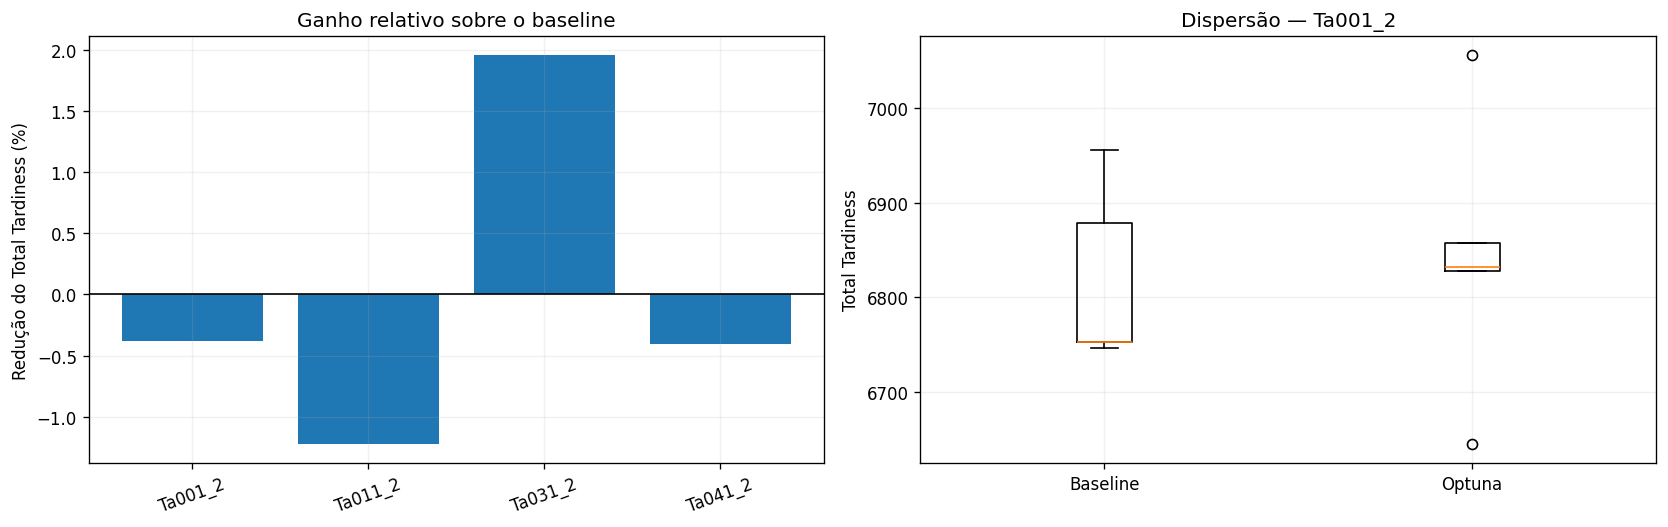

In [13]:
tab=RESUMO.pivot(index='instancia',columns='metodo',values='media')
tab['ganho_%']=100*(tab['SMA baseline']-tab['SMA + Optuna'])/tab['SMA baseline']
display(tab.round(3))
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
axs[0].bar(range(len(tab)),tab['ganho_%']);axs[0].axhline(0,c='k',lw=1)
axs[0].set_xticks(range(len(tab)),[Path(x).stem for x in tab.index],rotation=20)
axs[0].set(ylabel='Redução do Total Tardiness (%)',title='Ganho relativo sobre o baseline')
if len(INSTANCIAS_TESTE):
    nome=INSTANCIAS_TESTE[0]
    dados=[RESULTADOS[(RESULTADOS.instancia==nome)&(RESULTADOS.metodo==v)].fitness.values
          for v in ['SMA baseline','SMA + Optuna']]
    axs[1].boxplot(dados,tick_labels=['Baseline','Optuna'])
    axs[1].set(ylabel='Total Tardiness',title=f'Dispersão — {Path(nome).stem}')
plt.tight_layout();plt.show()

### 8.3. Evolução do melhor fitness ao longo das avaliações

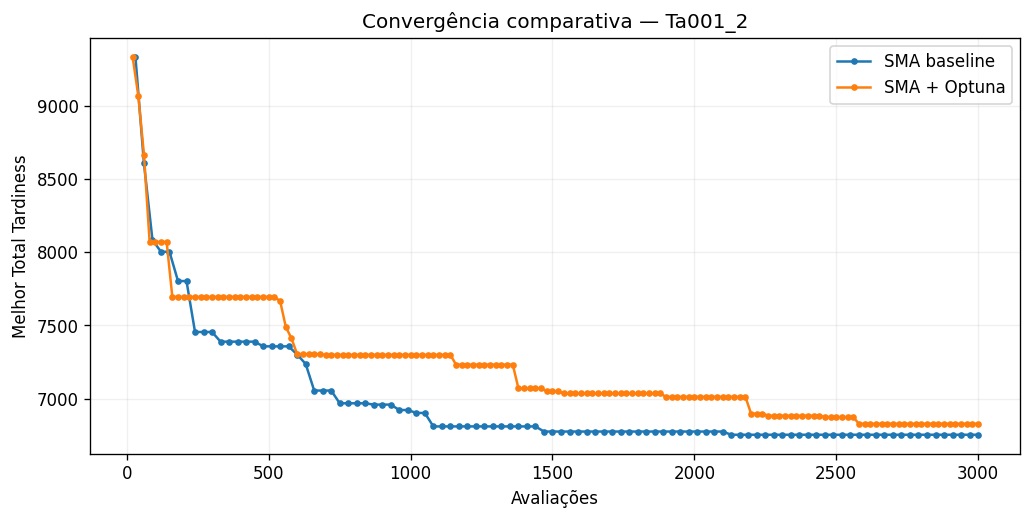

In [14]:
nome=INSTANCIAS_TESTE[0];seed=CONFIG['sementes_teste'][0]
fig,ax=plt.subplots(figsize=(10,4.5))
for metodo in ['SMA baseline','SMA + Optuna']:
    h=CURVAS[(nome,seed,metodo)]
    ax.plot(h[:,0],h[:,1],marker='.',label=metodo)
ax.set(xlabel='Avaliações',ylabel='Melhor Total Tardiness',title=f'Convergência comparativa — {Path(nome).stem}')
ax.legend();plt.show()

### 8.4. Comparação pareada por semente

A diferença entre os melhores fitness das duas configurações é calculada **na mesma instância e na mesma semente**. Isso permite observar em quantas repetições o Optuna superou a configuração fixa e quantas vezes a configuração fixa permaneceu melhor. Com poucas sementes, essas contagens são descritivas e não comprovam significância estatística.

In [15]:
PARES=RESULTADOS.pivot_table(index=['instancia','semente'],columns='metodo',
                             values='fitness').reset_index()
PARES['melhoria_absoluta']=PARES['SMA baseline']-PARES['SMA + Optuna']
PARES['melhoria_%']=100*PARES['melhoria_absoluta']/PARES['SMA baseline']
PARES['vencedor']=np.select(
    [PARES['melhoria_absoluta']>0,PARES['melhoria_absoluta']<0],
    ['SMA + Optuna','SMA baseline'],default='Empate')
print('COMPARAÇÃO PAREADA — MESMAS SEMENTES')
display(PARES.round(3))
print('\nRESUMO DE VITÓRIAS NAS INSTÂNCIAS RESERVADAS')
display(pd.crosstab(PARES['instancia'],PARES['vencedor']))
for nome,g in PARES.groupby('instancia'):
    print(f'{Path(nome).stem}: ganho médio pareado={g["melhoria_%"].mean():+.2f}% | '
          f'Optuna venceu em {(g["melhoria_absoluta"]>0).sum()} de {len(g)} sementes')
PARES.to_csv(OUT/'comparacao_pareada_sementes.csv',index=False)

COMPARAÇÃO PAREADA — MESMAS SEMENTES


metodo,instancia,semente,SMA + Optuna,SMA baseline,melhoria_absoluta,melhoria_%,vencedor
0,Large/Ta001_2.txt,401,6828.0,6753.0,-75.0,-1.111,SMA baseline
1,Large/Ta001_2.txt,503,6645.0,6746.0,101.0,1.497,SMA + Optuna
2,Large/Ta001_2.txt,607,6857.0,6879.0,22.0,0.320,SMA + Optuna
3,Large/Ta001_2.txt,709,6832.0,6753.0,-79.0,-1.170,SMA baseline
4,Large/Ta001_2.txt,811,7056.0,6956.0,-100.0,-1.438,SMA baseline
5,Large/Ta011_2.txt,401,8925.0,9305.0,380.0,4.084,SMA + Optuna
6,Large/Ta011_2.txt,503,8926.0,9274.0,348.0,3.752,SMA + Optuna
7,Large/Ta011_2.txt,607,8976.0,8652.0,-324.0,-3.745,SMA baseline
8,Large/Ta011_2.txt,709,8977.0,8279.0,-698.0,-8.431,SMA baseline
9,Large/Ta011_2.txt,811,9110.0,8862.0,-248.0,-2.798,SMA baseline



RESUMO DE VITÓRIAS NAS INSTÂNCIAS RESERVADAS


vencedor,SMA + Optuna,SMA baseline
instancia,,
Large/Ta001_2.txt,2,3
Large/Ta011_2.txt,2,3
Large/Ta031_2.txt,3,2
Large/Ta041_2.txt,2,3


Ta001_2: ganho médio pareado=-0.38% | Optuna venceu em 2 de 5 sementes
Ta011_2: ganho médio pareado=-1.43% | Optuna venceu em 2 de 5 sementes
Ta031_2: ganho médio pareado=+1.65% | Optuna venceu em 3 de 5 sementes
Ta041_2: ganho médio pareado=-0.54% | Optuna venceu em 2 de 5 sementes


## 9. Discussão e reprodutibilidade

A sintonia seleciona a combinação com menor **média de Total Tardiness** nas instâncias e sementes de treinamento. Essa configuração pode apresentar resultados diferentes nas instâncias reservadas, especialmente porque o estudo utiliza instâncias Small para selecionar parâmetros e instâncias Large para testar a transferência.

Na interpretação final, considerar simultaneamente:

- **Qualidade:** menor atraso médio e distribuição dos resultados por semente;
- **Estabilidade:** dispersão entre execuções e vitórias pareadas;
- **Custo:** avaliações equivalentes e diferença no tempo computacional;
- **Transferência:** comportamento da configuração selecionada nas instâncias reservadas.

Todos os parâmetros, trials e resultados finais são exportados em CSV e JSON. O melhor score da sintonia não deve ser apresentado como desempenho em teste.

In [16]:
manifesto={'experimento':'Sintonia SMA com Optuna','configuracao':CONFIG,
           'instancias_sintonia':INSTANCIAS_SINTONIA,'instancias_teste':INSTANCIAS_TESTE,
           'parametros_otimos':PARAMETROS_OTIMOS,'melhor_trial':int(estudo.best_trial.number),
           'tempo_sintonia':TEMPO_SINTONIA}
(OUT/'manifesto.json').write_text(json.dumps(manifesto,ensure_ascii=False,indent=2),encoding='utf8')
print('Resultados em:',OUT)
CONFIG_SELECIONADA = {
    'algoritmo':'Slime Mould Algorithm',
    'metodo_sintonia':'Optuna TPE',
    'parametros':PARAMETROS_OTIMOS,
    'score_sintonia':float(estudo.best_value),
    'trial_selecionada':int(estudo.best_trial.number+1),
    'avaliacoes_por_execucao':int(CONFIG['avaliacoes']),
}
(OUT/'melhor_configuracao.json').write_text(json.dumps(CONFIG_SELECIONADA,
    ensure_ascii=False,indent=2),encoding='utf8')
print('\nARQUIVOS DISPONÍVEIS')
for p in sorted(OUT.glob('*')):
    if p.is_file(): print(f'  • {p.name}')
print('\nConfiguração escolhida para ser reutilizada nos próximos experimentos:')
print(json.dumps(CONFIG_SELECIONADA,ensure_ascii=False,indent=2))

Resultados em: /kaggle/working/semana3_optuna

ARQUIVOS DISPONÍVEIS
  • avaliacao_final.csv
  • classificacao_trials.csv
  • comparacao_pareada_sementes.csv
  • manifesto.json
  • melhor_configuracao.json
  • resumo_avaliacao_final.csv
  • trials_optuna.csv

Configuração escolhida para ser reutilizada nos próximos experimentos:
{
  "algoritmo": "Slime Mould Algorithm",
  "metodo_sintonia": "Optuna TPE",
  "parametros": {
    "populacao": 20,
    "z": 0.13411326915217497
  },
  "score_sintonia": 2208.6666666666665,
  "trial_selecionada": 2,
  "avaliacoes_por_execucao": 3000
}
